# **IMPORTING LIBRARIES AND READING CSV FILE**

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/medical_diagnosis_classification.csv")
df


,blood_sugar,bmi_dup,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease
0,High,NaN,M,89.0,109.9,203.0,No,NaN,P40000,1.0
1,Lw,29.0,F,88.0,118.7,165.9,NO,29.0,NaN,0.0
2,HIGH,19.2,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0
3,High,22.0,M,NaN,121.3,204.7,N,22.0,P40003,0.0
4,NORMAL,28.0,M,36.0,unknown,202.7,Yes,28.0,P40004,0.0
...,...,...,...,...,...,...,...,...,...,...
260,High,20.3,M,21.0,103.8,184.0,NO,20.3,P40006,NaN
261,HIGH,18.6,F,35.0,130.9,227.7,o,18.6,P40214,0.0
262,HIGH,18.6,F,35.0,130.9,227.7,o,18.6,P40214,0.0
263,Normal,26.6,M,50.0,110.6,253.5,NO,26.6,P40045,0.0


## **DESCRIPTIVE STATISTICS**

In [77]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   blood_sugar     241 non-null    object 
 1   bmi_dup         239 non-null    float64
 2   sex             246 non-null    object 
 3   age             245 non-null    float64
 4   blood_pressure  246 non-null    object 
 5   cholesterol     234 non-null    float64
 6   smoker          248 non-null    object 
 7   bmi             239 non-null    float64
 8   patient_id      243 non-null    object 
 9   disease         237 non-null    float64
dtypes: float64(5), object(5)
memory usage: 20.8+ KB


,bmi_dup,age,cholesterol,bmi,disease
count,239.000000,245.000000,234.000000,239.000000,237.000000
mean,27.117155,50.975510,201.117094,27.117155,0.147679
std,6.975810,28.147289,34.665406,6.975810,0.355533
min,15.300000,0.000000,106.700000,15.300000,0.000000
25%,21.300000,27.000000,176.575000,21.300000,0.000000
50%,26.100000,51.000000,202.700000,26.100000,0.000000
75%,32.750000,76.000000,224.775000,32.750000,0.000000
max,40.000000,99.000000,308.500000,40.000000,1.000000


# **DATA PREPROCESSING**

# FILLING THE MISSING VALUES

In [78]:
df["age"] = df["age"].fillna(df["age"].median())
print(df["age"])

0      89.0
1      88.0
2      80.0
3      51.0
4      36.0
       ... 
260    21.0
261    35.0
262    35.0
263    50.0
264    34.0
Name: age, Length: 265, dtype: float64


In [79]:
df["bmi"] = df["bmi"].fillna(df["bmi"].median())
print(df["bmi"])

0      26.1
1      29.0
2      19.2
3      22.0
4      28.0
       ... 
260    20.3
261    18.6
262    18.6
263    26.6
264    33.1
Name: bmi, Length: 265, dtype: float64


In [80]:
df["cholesterol"] = df["cholesterol"].fillna(df["cholesterol"].median())
print(df["cholesterol"])

0      203.0
1      165.9
2      166.8
3      204.7
4      202.7
       ...  
260    184.0
261    227.7
262    227.7
263    253.5
264    159.4
Name: cholesterol, Length: 265, dtype: float64


In [81]:
df["disease"] = df["disease"].fillna(df["disease"].median())
print(df["disease"])

0      1.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
260    0.0
261    0.0
262    0.0
263    0.0
264    0.0
Name: disease, Length: 265, dtype: float64


In [82]:
df["blood-sugar"]=df["blood_sugar"].fillna(df["blood_sugar"].mode()[0])
print(df["blood_sugar"])

0        High
1          Lw
2        HIGH
3        High
4      NORMAL
        ...  
260      High
261      HIGH
262      HIGH
263    Normal
264    Normal
Name: blood_sugar, Length: 265, dtype: object


In [83]:
df["sex"] = df["sex"].fillna(df["sex"].mode()[0])
print(df["sex"])

0      M
1      F
2      M
3      M
4      M
      ..
260    M
261    F
262    F
263    M
264    M
Name: sex, Length: 265, dtype: object


In [84]:
df["smoker"] = df["smoker"].fillna(df["smoker"].mode()[0])
print(df["smoker"])

0       No
1       NO
2      Yes
3        N
4      Yes
      ... 
260     NO
261      o
262      o
263     NO
264      o
Name: smoker, Length: 265, dtype: object


# CASE CORRECTION OF CATEGORICAL DATA

In [85]:
df['blood_sugar'] = df['blood_sugar'].str.strip().str.lower()

df['blood_sugar'] = df['blood_sugar'].replace({
    'high': 'High', 'hih': 'High', 'hig': 'High',
    'normal': 'Normal', 'norml': 'Normal', 'norml': 'Normal',
    'low': 'Low', 'lw': 'Low', 'lo': 'Low'
})
print(df['blood_sugar'])

0        High
1         Low
2        High
3        High
4      Normal
        ...  
260      High
261      High
262      High
263    Normal
264    Normal
Name: blood_sugar, Length: 265, dtype: object


In [86]:
df['smoker'] = df['smoker'].str.strip().str.lower()

df['smoker'] = df['smoker'].replace({
    'yes': 'Yes', 'ys': 'Yes', 'ye': 'Yes',
    'no': 'No', 'n': 'No', 'o': 'No'
})
print(df['smoker'])

0       No
1       No
2      Yes
3       No
4      Yes
      ... 
260     No
261     No
262     No
263     No
264     No
Name: smoker, Length: 265, dtype: object


# DROP DUPLICATES

In [87]:
df.drop(columns = ["bmi_dup"])

,blood_sugar,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease,blood-sugar
0,High,M,89.0,109.9,203.0,No,26.1,P40000,1.0,High
1,Low,F,88.0,118.7,165.9,No,29.0,NaN,0.0,Lw
2,High,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0,HIGH
3,High,M,51.0,121.3,204.7,No,22.0,P40003,0.0,High
4,Normal,M,36.0,unknown,202.7,Yes,28.0,P40004,0.0,NORMAL
...,...,...,...,...,...,...,...,...,...,...
260,High,M,21.0,103.8,184.0,No,20.3,P40006,0.0,High
261,High,F,35.0,130.9,227.7,No,18.6,P40214,0.0,HIGH
262,High,F,35.0,130.9,227.7,No,18.6,P40214,0.0,HIGH
263,Normal,M,50.0,110.6,253.5,No,26.6,P40045,0.0,Normal


In [88]:
df.drop(columns = ["patient_id"])

,blood_sugar,bmi_dup,sex,age,blood_pressure,cholesterol,smoker,bmi,disease,blood-sugar
0,High,NaN,M,89.0,109.9,203.0,No,26.1,1.0,High
1,Low,29.0,F,88.0,118.7,165.9,No,29.0,0.0,Lw
2,High,19.2,M,80.0,107.5,166.8,Yes,19.2,0.0,HIGH
3,High,22.0,M,51.0,121.3,204.7,No,22.0,0.0,High
4,Normal,28.0,M,36.0,unknown,202.7,Yes,28.0,0.0,NORMAL
...,...,...,...,...,...,...,...,...,...,...
260,High,20.3,M,21.0,103.8,184.0,No,20.3,0.0,High
261,High,18.6,F,35.0,130.9,227.7,No,18.6,0.0,HIGH
262,High,18.6,F,35.0,130.9,227.7,No,18.6,0.0,HIGH
263,Normal,26.6,M,50.0,110.6,253.5,No,26.6,0.0,Normal


In [89]:
df.drop(columns = ["blood-sugar"])

,blood_sugar,bmi_dup,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease
0,High,NaN,M,89.0,109.9,203.0,No,26.1,P40000,1.0
1,Low,29.0,F,88.0,118.7,165.9,No,29.0,NaN,0.0
2,High,19.2,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0
3,High,22.0,M,51.0,121.3,204.7,No,22.0,P40003,0.0
4,Normal,28.0,M,36.0,unknown,202.7,Yes,28.0,P40004,0.0
...,...,...,...,...,...,...,...,...,...,...
260,High,20.3,M,21.0,103.8,184.0,No,20.3,P40006,0.0
261,High,18.6,F,35.0,130.9,227.7,No,18.6,P40214,0.0
262,High,18.6,F,35.0,130.9,227.7,No,18.6,P40214,0.0
263,Normal,26.6,M,50.0,110.6,253.5,No,26.6,P40045,0.0


# **EXPLORATORY DATA ANALYSIS**

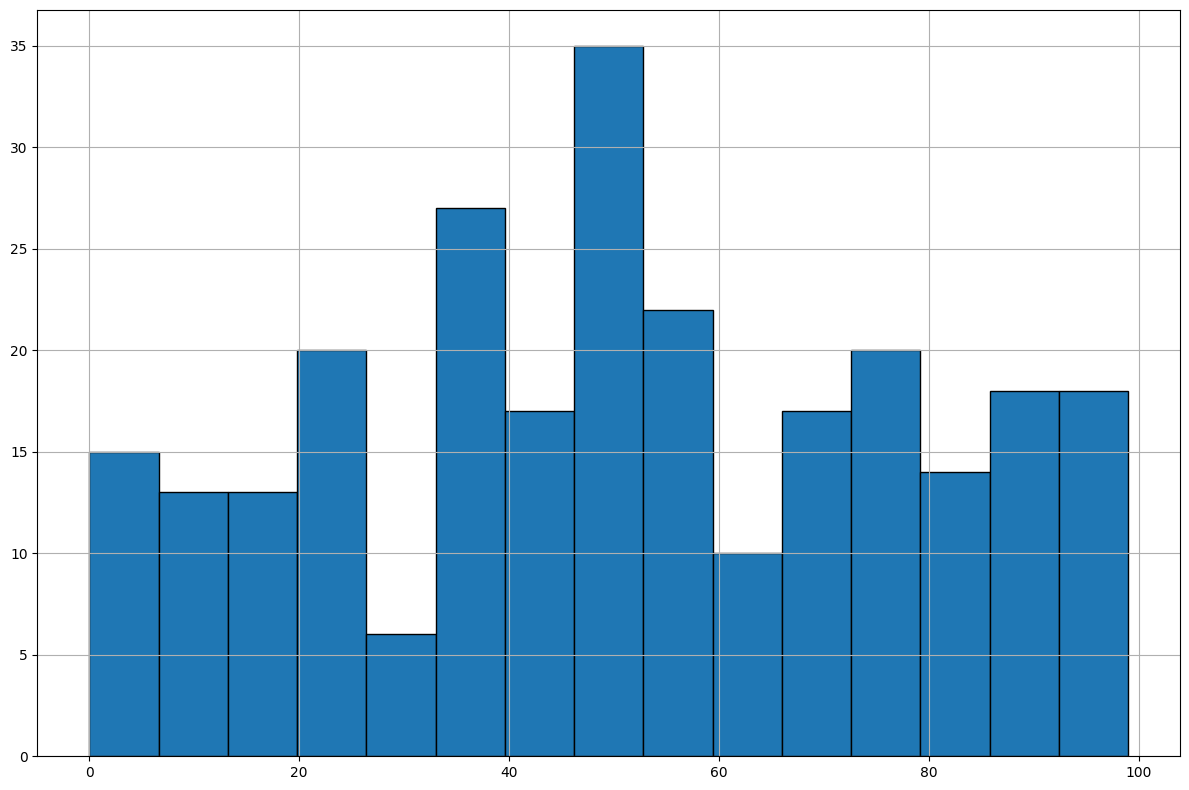

In [90]:
df["age"].hist(
    figsize=(12,8), bins=15, edgecolor = 'black'
)

plt.tight_layout()
plt.show()

## Most patients are concentrated in the middle-age groups, with ages spread across approximately 0–100 years.

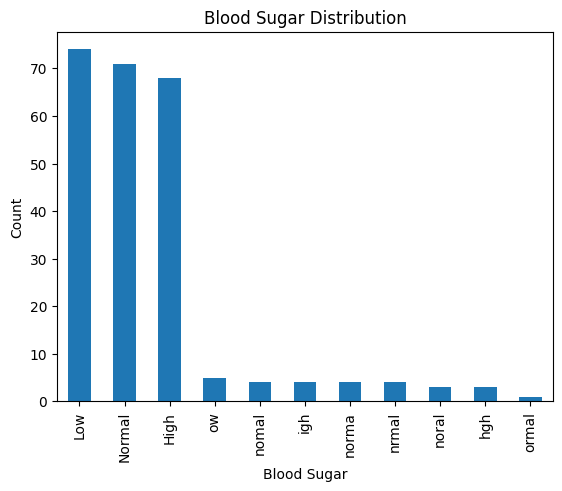

In [101]:
df['blood_sugar'].value_counts().plot(kind='bar')
plt.title('Blood Sugar Distribution')
plt.xlabel('Blood Sugar')
plt.ylabel('Count')
plt.show()

## The graph shows different blood sugar categories, with labels representing similar values.

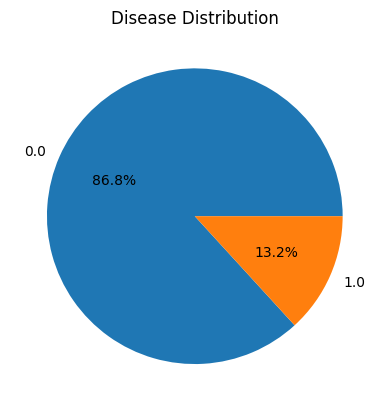

In [92]:
df['disease'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Disease Distribution')
plt.ylabel('')
plt.show()

## Disease class 0 accounts for 86.8% of records, while class 1 accounts for 13.2%.

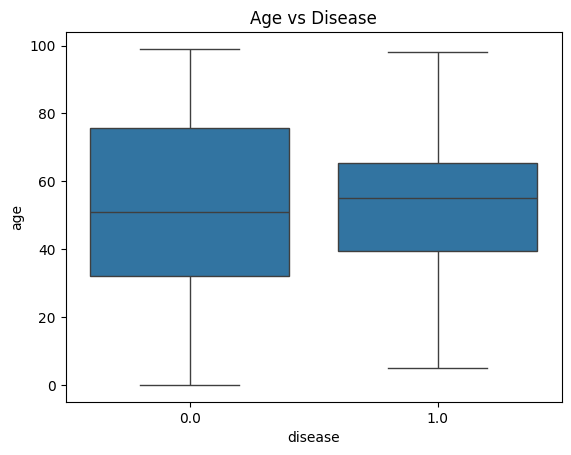

In [93]:
sns.boxplot(x='disease', y='age', data=df)
plt.title('Age vs Disease')
plt.show()

## Patients in disease class 1 have a slightly higher median age than patients in class 0.

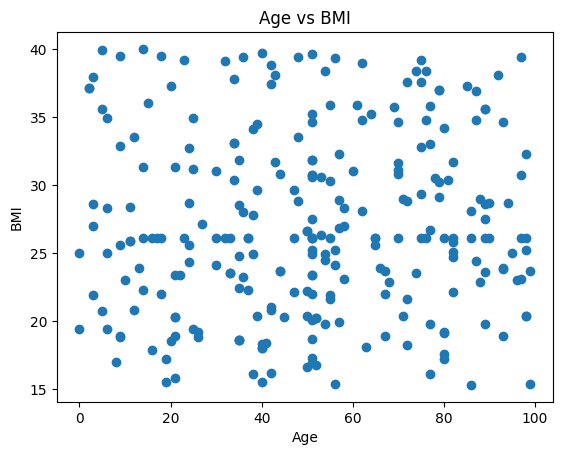

In [94]:
plt.scatter(df['age'], df['bmi'])
plt.xlabel('Age')
plt.ylabel('BMI')
plt.title('Age vs BMI')
plt.show()

## Age and BMI show no clear linear relationship, as the data points are widely scattered.

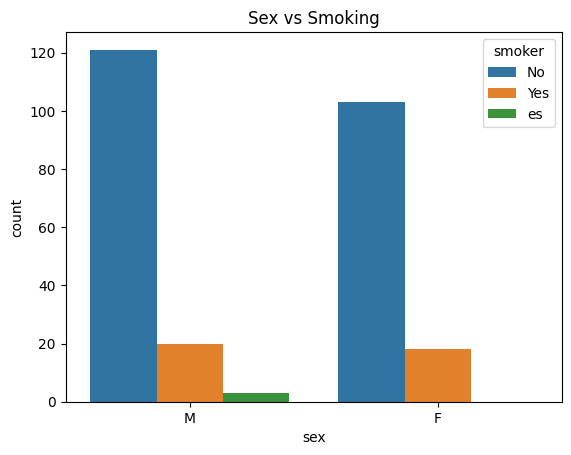

In [95]:
sns.countplot(data=df, x='sex', hue='smoker')
plt.title('Sex vs Smoking')
plt.show()

## Smoking categories are distributed across both male and female patients.

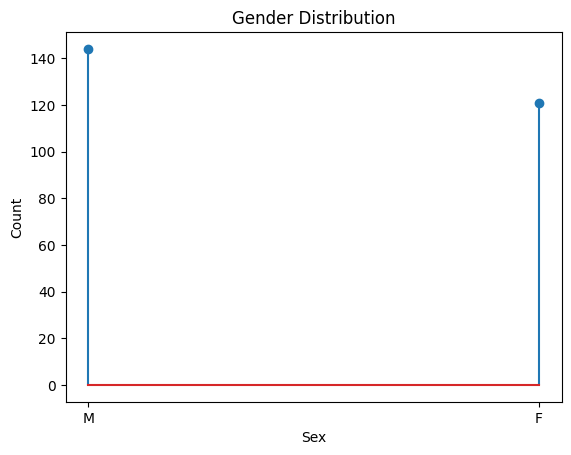

In [96]:
data = df['sex'].value_counts()

plt.stem(data.index, data.values)
plt.title('Gender Distribution')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()

## Male patients are higher in number compared to female patients.

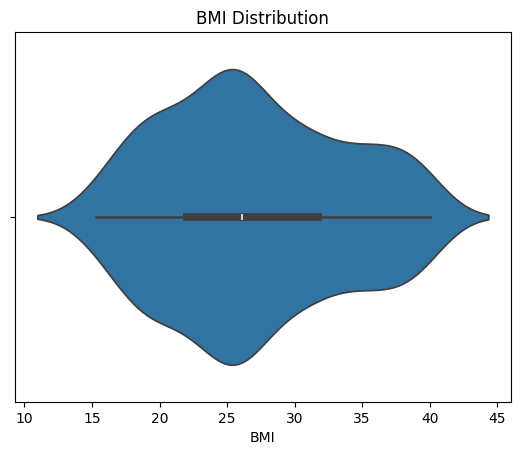

In [97]:
sns.violinplot(x=df['bmi'])
plt.title('BMI Distribution')
plt.xlabel('BMI')
plt.show()

## BMI values are mainly concentrated in the middle range, approximately between 15 and 40.

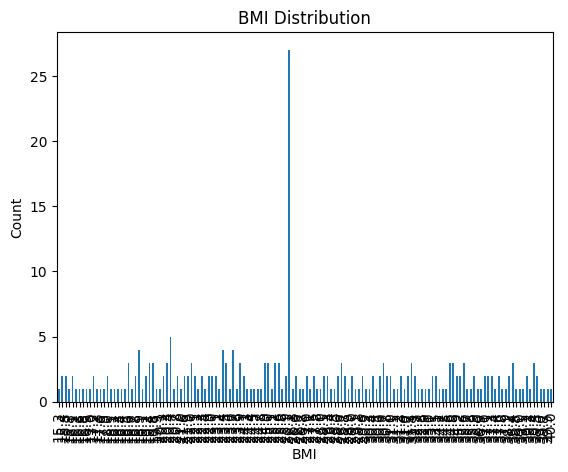

In [98]:
df['bmi'].value_counts().sort_index().plot(kind='bar')
plt.title('BMI Distribution')
plt.xlabel('BMI')
plt.ylabel('Count')
plt.show()

## BMI values show varying frequencies, with some BMI values occurring more frequently than others

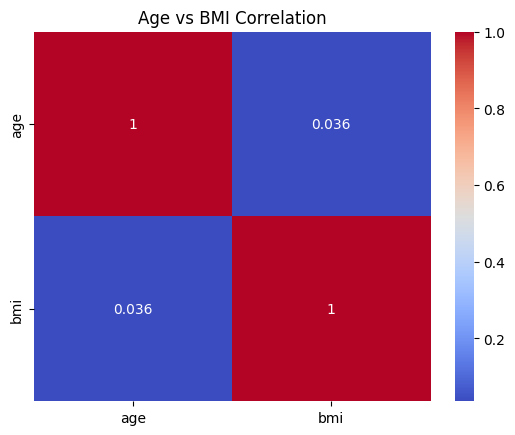

In [99]:
sns.heatmap(df[['age', 'bmi']].corr(), annot=True, cmap='coolwarm')
plt.title('Age vs BMI Correlation')
plt.show()

## Age and BMI have a correlation of approximately 0.036, indicating a very weak positive relationship.

# **INSIGHTS OR OUTCOMES**

## Most patients do not have the disease: Out of 197 cleaned records, 167 patients (85%) are healthy and 30 patients (15%) have the disease, meaning the dataset is heavily imbalanced.

## A lot of raw data needed cleaning: Over a quarter of the original 265 rows had to be fixed or removed because of missing values, spelling mistakes (like 'Lw' or 'Hig'), duplicates, and extreme outliers.

## No single measurement strongly predicts the disease on its own: Age, blood pressure, cholesterol, and BMI all have very weak direct correlations with the disease (all below 0.10), meaning predicting the disease requires looking at multiple factors together (like smoking and blood sugar levels) rather than just one vital sign.